In [20]:
# SECTION 1:
#Q1 Load the crop_yield.csv file
import pandas as pd
df=pd.read_csv("~/Documents/Assignment 16/crop_yield.csv")
print(df.shape)

(3000, 9)


In [21]:
#Q2 Display the first 10 rows
df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [22]:
#Q3 Check missing values in each column
df.isna().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [23]:
#Q4 View the data types of all columns
df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [24]:
#Q5 Get the statistical summary of numeric columns#Q5 Get the statistical summary of numeric columns
round(df.describe(),2)

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.00,2856.00,3000.00
mean,2014.23,4.42,39657.78
std,407.85,0.98,8405.08
min,1500.00,3.00,20068.00
25%,1500.00,4.00,30000.00
50%,2000.00,4.00,40000.00
75%,2500.00,5.00,50000.00
max,2500.00,6.00,50000.00


In [25]:
#Q6 Get the statistical summary of object columns
df.describe(include="str")

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [28]:
# SECTION 2 :
##Q7 Remove rows with missing YIELD_KG values
crop_df=df.dropna(subset=["YIELD_KG"])
print(crop_df.shape)

(2670, 9)


In [29]:
#Q8 Fill missing AREA_ACRES values with the mean
crop_df['AREA_ACRES']=crop_df['AREA_ACRES'].fillna(crop_df['AREA_ACRES'].mean())
print(crop_df['AREA_ACRES'].isna().sum())

0


In [30]:
#Q9 Replace missing DISTRICT values with Unknown
crop_df['DISTRICT']=crop_df['DISTRICT'].fillna('Unknown')
print(crop_df['DISTRICT'].isna().sum())

0


In [31]:
#Q10 Replace missing FERTILIZER_USED values with No
crop_df['FERTILIZER_USED']=crop_df['FERTILIZER_USED'].fillna('No')
print(crop_df['FERTILIZER_USED'].isnull().sum())

0


In [32]:
#Q11 Replace missing YIELD_VALUE values with the mean
crop_df['YIELD_VALUE']=crop_df['YIELD_VALUE'].fillna(crop_df['YIELD_VALUE'].mean())
print(crop_df['YIELD_VALUE'].isnull().sum())

0


In [33]:
#Q12 Convert HARVEST_DATE to datetime format
crop_df['HARVEST_DATE']=pd.to_datetime(crop_df['HARVEST_DATE'],format='%d/%m/%Y',errors='coerce')
print(crop_df['HARVEST_DATE'].dtype)

datetime64[us]


In [34]:
#Q13 Remove F from FARM_ID and convert to integer
crop_df['FARM_ID']=crop_df['FARM_ID'].str.replace('F','')
crop_df['FARM_ID']=crop_df['FARM_ID'].astype(int)
print(crop_df['FARM_ID'].head())

0    1
1    2
2    3
3    4
4    5
Name: FARM_ID, dtype: int64


In [36]:
#Q14 Recheck missing values after cleaning
print(crop_df.isnull().sum())
#Q15 Recheck data types after cleaning
print(crop_df.dtypes)

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64
FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object


In [37]:
#Section 3:
#Q16 Calculate the total yield of each crop type
total_yield=crop_df.groupby('CROP_TYPE').agg({'YIELD_KG':'sum'})
print(total_yield)

            YIELD_KG
CROP_TYPE           
Maize      1112500.0
Rice       1638000.0
Sugarcane   592000.0
Wheat      2035500.0


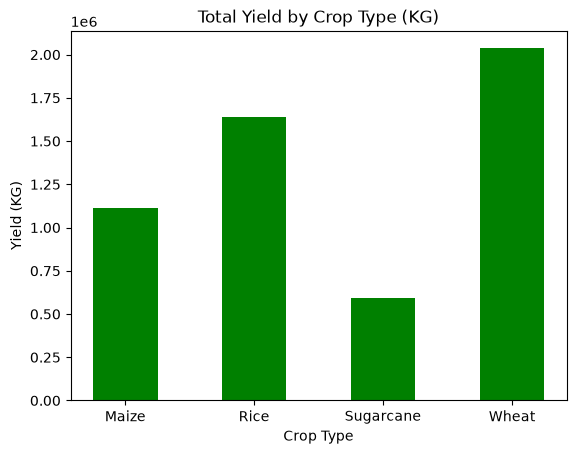

In [38]:
#Q17 Plot a bar chart of total yield by crop type
import matplotlib.pyplot as plt
plt.bar(total_yield.index,total_yield['YIELD_KG'],color='green',width=0.5)
plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')
plt.title('Total Yield by Crop Type (KG)')
plt.show()

In [39]:
#Q18 Create a pivot table summarizing total yield by harvest date
yield_pivot=crop_df.pivot_table(values='YIELD_KG',index='HARVEST_DATE',aggfunc='sum')
print(yield_pivot)

              YIELD_KG
HARVEST_DATE          
2023-01-01      1500.0
2023-01-02      1500.0
2023-01-03      2500.0
2023-01-04      1500.0
2023-01-05      1500.0
...                ...
2031-03-15      1500.0
2031-03-16      2000.0
2031-03-17      2000.0
2031-03-18      2000.0
2031-03-19      2500.0

[2670 rows x 1 columns]


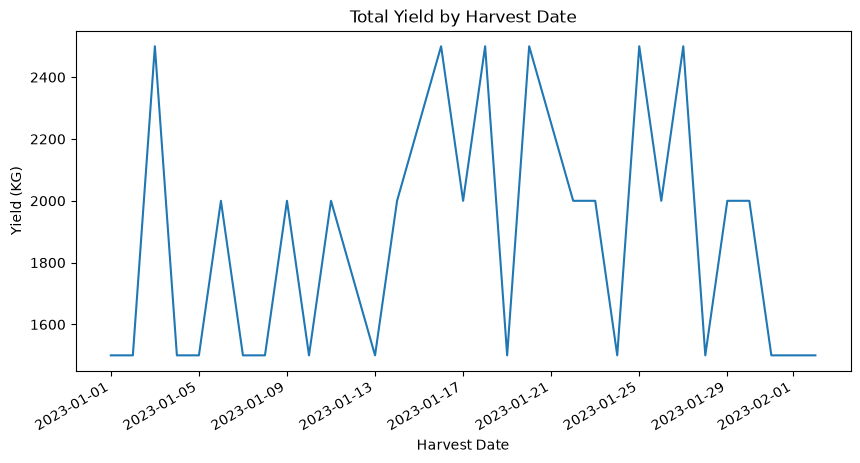

In [44]:
yield_pivot.head(30).plot(kind='line', figsize=(10, 5), legend=False)
plt.title('Total Yield by Harvest Date')
plt.xlabel('Harvest Date')
plt.ylabel('Yield (KG)')
plt.show()